Exploration for Q1

In [1]:
import sys
from pathlib import Path

# find the repo root (the folder that contains src/), wherever this notebook is saved
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "qkit.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

import config as cfg
import qkit


In [2]:
df = qkit.county_year(cfg.Q1_YEARS).merge(
    qkit.covariates(cfg.Q1_YEARS).drop(columns="county_name"),
    on=["fips", "year"], how="left", validate="1:1",
)

# Wilkin has no reporting food shelf: its activity is a true zero, not unknown
no_activity = df["households"].isna() & df["fi_persons"].notna()
for m in ["households", "pounds", "individuals"]:
    df.loc[no_activity, m] = 0
    df.loc[no_activity, f"{m}_per_fi"] = 0
df.loc[no_activity, "months_observed"] = 0

print(df.shape)
df.dtypes


(261, 35)


fips                               str
county_name                        str
year                             int64
households                     float64
pounds                         float64
individuals                    float64
months_observed                float64
source_edition                     str
fi_rate                        float64
fi_persons                     float64
child_fi_rate                  float64
fi_children                    float64
cost_per_meal                  float64
annual_shortfall               float64
rucc_2013                      float64
rucc_2023                      float64
snap_threshold                 float64
pct_fi_below_snap_threshold    float64
pct_fi_above_snap_threshold    float64
households_per_fi              float64
pounds_per_fi                  float64
individuals_per_fi             float64
population                       int64
households_census                int64
poverty_rate                   float64
child_poverty_rate       

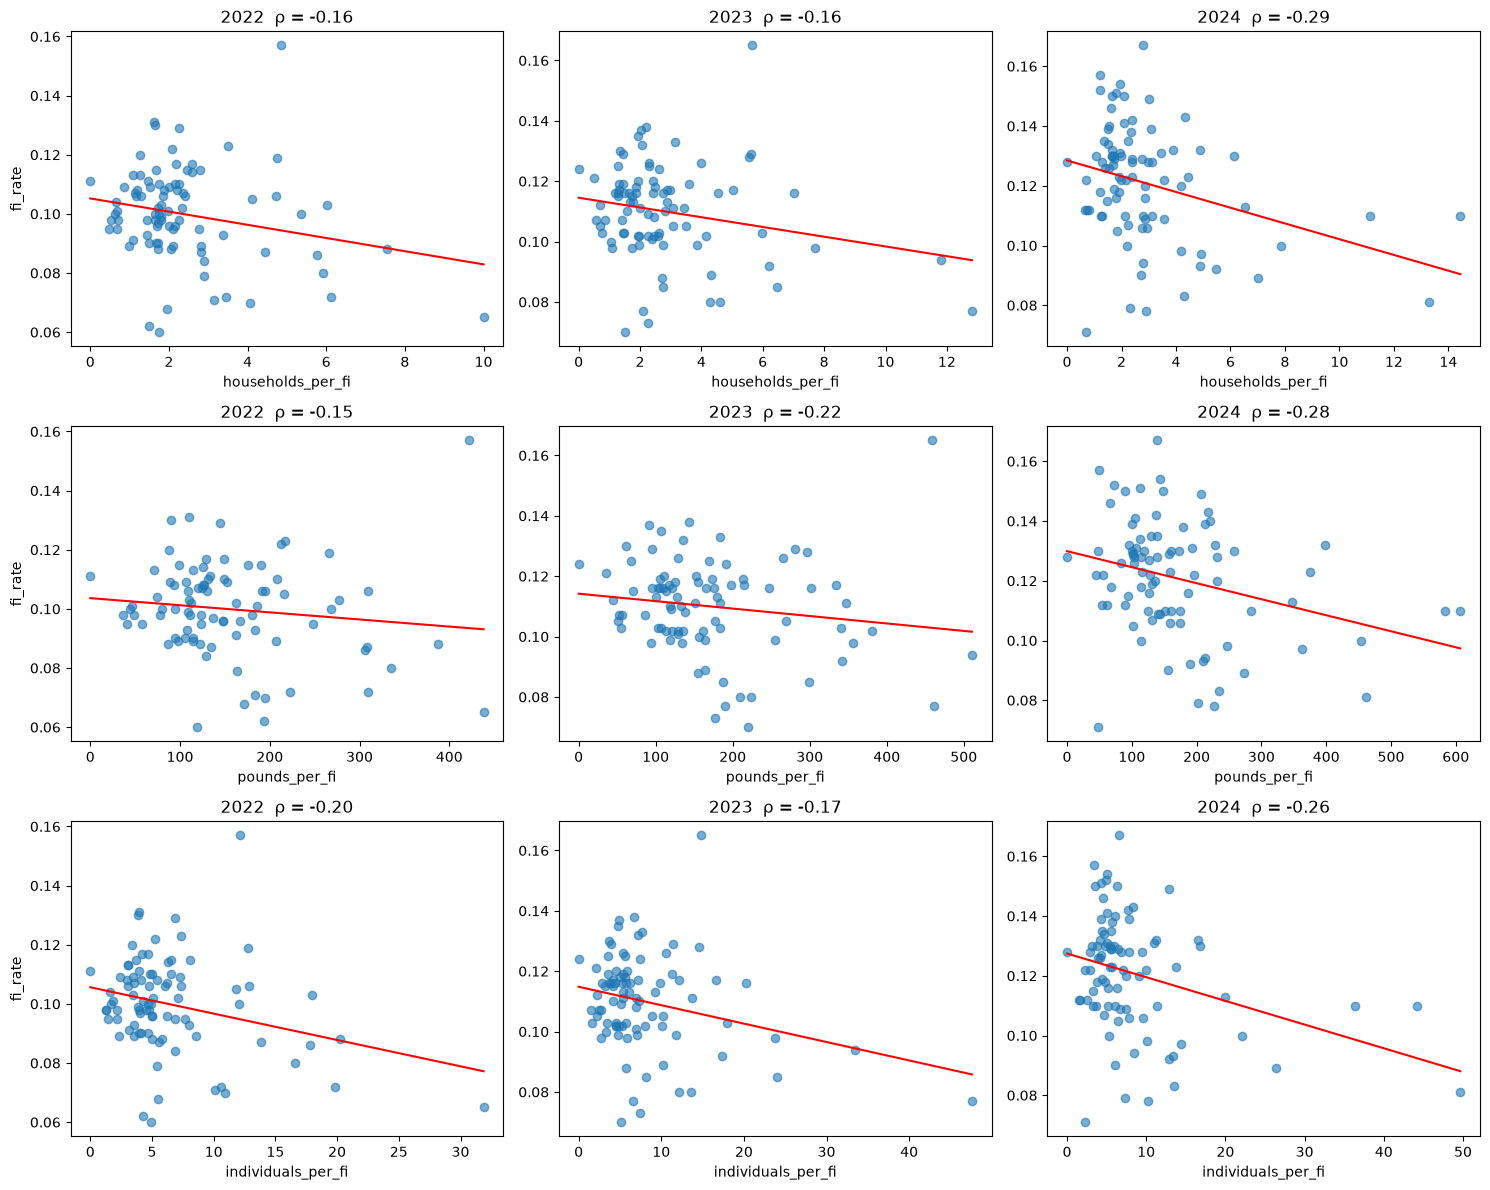

metric,households_per_fi,individuals_per_fi,pounds_per_fi
year,,,
2022,-0.164,-0.195,-0.145
2023,-0.163,-0.173,-0.219
2024,-0.293,-0.262,-0.285


In [3]:
metrics = ["households_per_fi", "pounds_per_fi", "individuals_per_fi"]
years = sorted(df["year"].unique())
fig, axes = plt.subplots(len(metrics), len(years), figsize=(5 * len(years), 4 * len(metrics)))

rows = []
for i, met in enumerate(metrics):
    for j, yr in enumerate(years):
        g = df[df["year"] == yr].dropna(subset=[met, "fi_rate"])
        ax = axes[i, j]
        ax.scatter(g[met], g["fi_rate"], alpha=0.6)
        m, b = np.polyfit(g[met], g["fi_rate"], 1)
        xs = np.linspace(g[met].min(), g[met].max(), 100)
        ax.plot(xs, m * xs + b, color="red")
        rho = g[met].corr(g["fi_rate"], method="spearman")
        ax.set_title(f"{yr}  ρ = {rho:.2f}")
        ax.set_xlabel(met)
        if j == 0:
            ax.set_ylabel("fi_rate")
        rows.append({"year": yr, "metric": met, "spearman": rho, "n": len(g)})

plt.tight_layout()
plt.show()
pd.DataFrame(rows).pivot(index="year", columns="metric", values="spearman").round(3)


### Two caveats on those correlations
1. **The negative sign is partly built in.** The x-axis divides by `fi_persons` and the
   y-axis (`fi_rate`) multiplies by it, so the two would correlate negatively even with
   random data. Activity per 1,000 *residents* does not share that term; the table below
   shows it next to the per-FI-person version. The defensible statement is *activity does
   not rise with need intensity* — not *higher need means less activity per person*.
   The residual ranking further down does not have this problem.
2. **2024 uses a different MMG edition** (2026) from 2022–23 (2025). Feeding America
   re-estimates the model each edition, so the stronger 2024 numbers may be a modelling
   change rather than a real shift. Do not describe it as a trend.

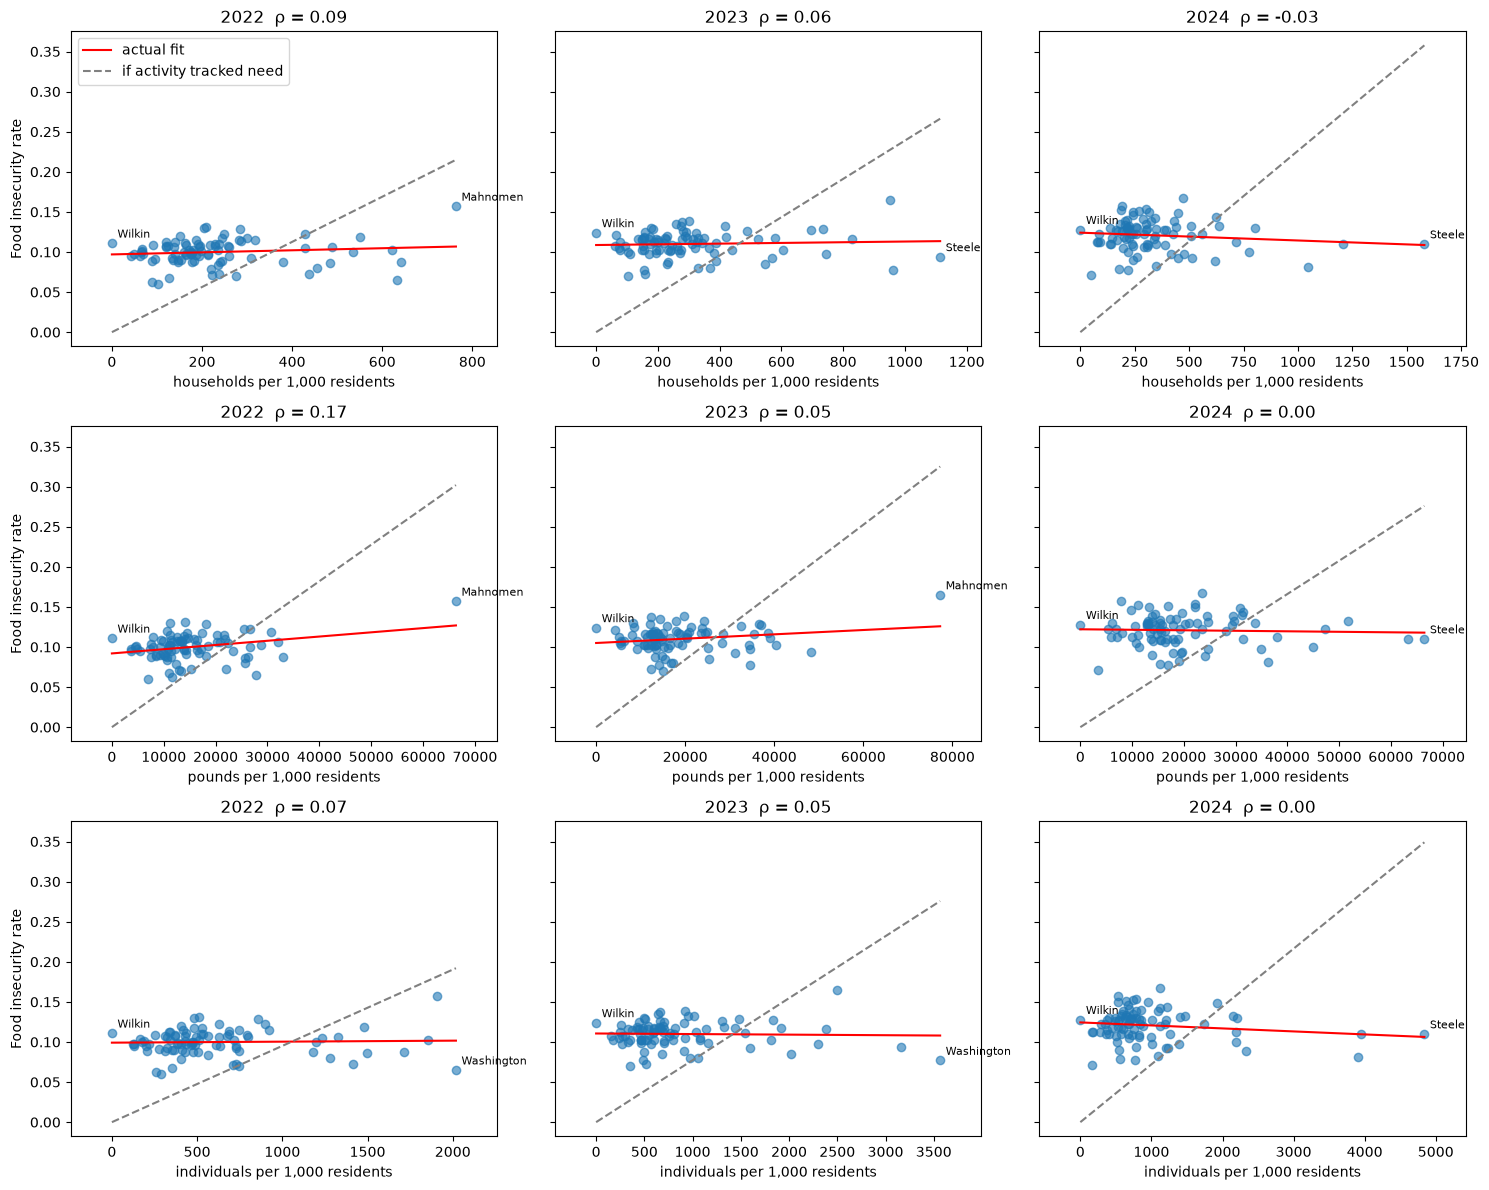

In [4]:
count_metrics = ["households", "pounds", "individuals"]
years = sorted(df["year"].unique())
fig, axes = plt.subplots(len(count_metrics), len(years),
                         figsize=(5 * len(years), 4 * len(count_metrics)), sharey=True)

for i, met in enumerate(count_metrics):
    for j, yr in enumerate(years):
        g = df[df["year"] == yr]
        ax = axes[i, j]

        x = 1e3 * g[met] / g["population"]           # activity per 1,000 residents
        y = g["fi_rate"]
        k = g[met].sum() / g["fi_persons"].sum()      # statewide activity per food-insecure person

        ax.scatter(x, y, alpha=0.6)
        ax.margins(x=0.12)   # room for the county labels at the right edge
        m, b = np.polyfit(x, y, 1)
        xs = np.linspace(0, x.max(), 100)
        ax.plot(xs, m * xs + b, color="red", label="actual fit")
        ax.plot(xs, xs / (1e3 * k), color="grey", linestyle="--", label="if activity tracked need")

        # name the two counties a reader will ask about: the far-right dot and Wilkin at zero
        for name in [g.loc[x.idxmax(), "county_name"], "Wilkin"]:
            r = g[g["county_name"] == name].iloc[0]
            ax.annotate(name, (1e3 * r[met] / r["population"], r["fi_rate"]),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)

        rho = x.corr(y, method="spearman")
        ax.set_title(f"{yr}  ρ = {rho:.2f}")
        ax.set_xlabel(f"{met} per 1,000 residents")
        if j == 0:
            ax.set_ylabel("Food insecurity rate")

axes[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()


In [5]:
rows = []
for met in ["households", "pounds", "individuals"]:
    for yr in years:
        g = df[df["year"] == yr]
        rows.append({"year": yr, "metric": met,
                     "per food-insecure person": g[f"{met}_per_fi"].corr(g["fi_rate"], method="spearman"),
                     "per 1,000 residents": (1e3 * g[met] / g["population"]).corr(g["fi_rate"], method="spearman")})
pd.DataFrame(rows).set_index(["year", "metric"]).round(3)

,,per food-insecure person,"per 1,000 residents"
year,metric,,
2022,households,-0.164,0.093
2023,households,-0.163,0.057
2024,households,-0.293,-0.029
2022,pounds,-0.145,0.167
2023,pounds,-0.219,0.050
2024,pounds,-0.285,0.003
2022,individuals,-0.195,0.073
2023,individuals,-0.173,0.047
2024,individuals,-0.262,0.001


## The fit itself: log activity on log food-insecure persons
One fit per metric and year, nine in all, before anything is averaged. Both axes are on a
log scale, so the slope reads as a percentage: a slope of 1.2 means that a county with 1%
more food-insecure people has about 1.2% more activity.

- **Grey dashed line, slope 1:** what proportional service would look like. Twice the
  need, twice the activity.
- **Red line:** what the data shows.
- **Distance of a dot from the red line:** that county's residual, used in the ranking
  below.

This view forms no ratio, so it has neither the built-in negative tilt of the
per-food-insecure-person chart nor the leftover county size of the per-1,000-residents
chart. R² will be high here because both axes grow with county size; the slope and the
residuals carry the finding, not R². Intervals use robust (HC3) standard errors. Wilkin
is left out because the log of zero is undefined.

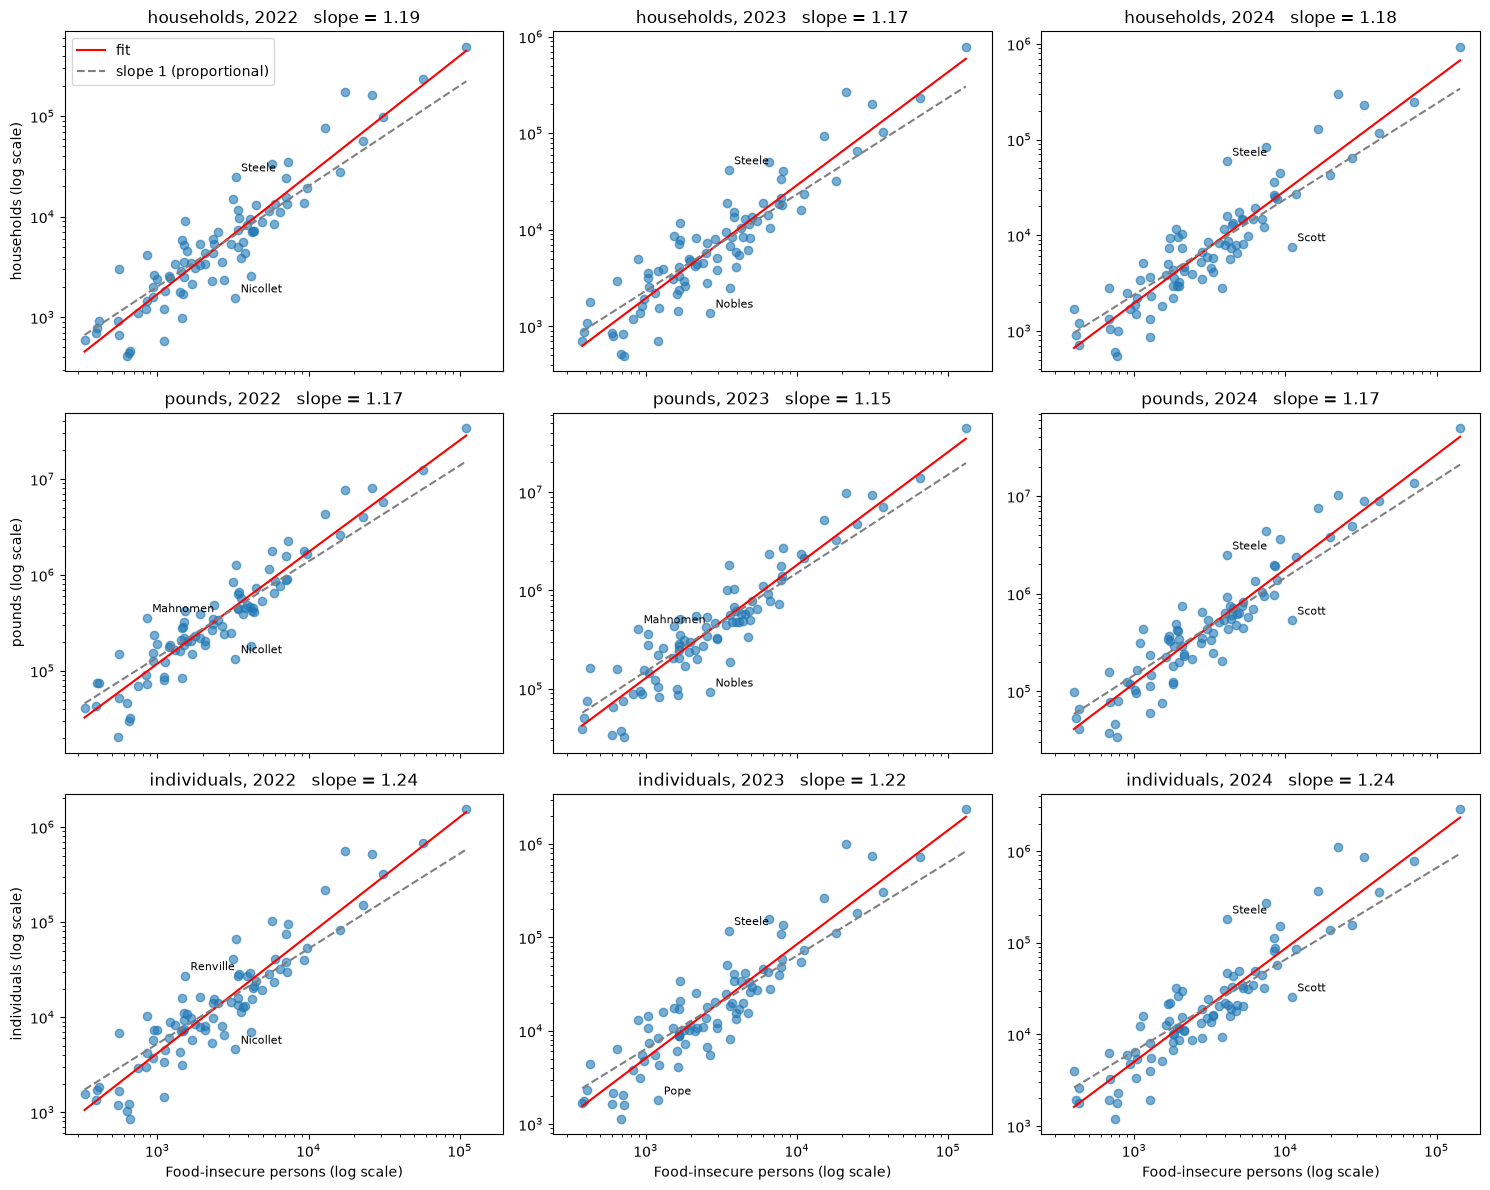

slope  ci_low  ci_high     r2   n
metric      year                                   
households  2022  1.186   1.087    1.286  0.850  86
            2023  1.172   1.067    1.278  0.836  86
            2024  1.178   1.067    1.289  0.845  86
pounds      2022  1.165   1.078    1.253  0.884  86
            2023  1.149   1.057    1.241  0.866  86
            2024  1.172   1.080    1.264  0.870  86
individuals 2022  1.241   1.137    1.345  0.855  86
            2023  1.222   1.112    1.332  0.845  86
            2024  1.237   1.120    1.354  0.848  86

In [6]:
count_metrics = ["households", "pounds", "individuals"]
years = sorted(df["year"].unique())
fig, axes = plt.subplots(len(count_metrics), len(years),
                         figsize=(5 * len(years), 4 * len(count_metrics)), sharex=True)

fit_rows = []
for i, met in enumerate(count_metrics):
    for j, yr in enumerate(years):
        g = df[(df["year"] == yr) & (df[met] > 0)].copy()
        fit = smf.ols(f"np.log({met}) ~ np.log(fi_persons)", data=g).fit(cov_type="HC3")
        intercept, slope = fit.params.iloc[0], fit.params.iloc[1]
        ci_low, ci_high = fit.conf_int().iloc[1]
        g["resid"] = fit.resid

        ax = axes[i, j]
        ax.scatter(g["fi_persons"], g[met], alpha=0.6)
        xs = np.geomspace(g["fi_persons"].min(), g["fi_persons"].max(), 50)
        ax.plot(xs, np.exp(intercept) * xs ** slope, color="red", label="fit")

        # slope 1 through the middle of the data: proportional service
        k = np.exp(np.log(g[met]).mean() - np.log(g["fi_persons"]).mean())
        ax.plot(xs, k * xs, color="grey", linestyle="--", label="slope 1 (proportional)")

        # name the county furthest below the line and the one furthest above
        for idx in (g["resid"].idxmin(), g["resid"].idxmax()):
            ax.annotate(g.loc[idx, "county_name"], (g.loc[idx, "fi_persons"], g.loc[idx, met]),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(f"{met}, {yr}   slope = {slope:.2f}")
        if i == len(count_metrics) - 1:
            ax.set_xlabel("Food-insecure persons (log scale)")
        if j == 0:
            ax.set_ylabel(f"{met} (log scale)")

        fit_rows.append({"metric": met, "year": yr, "slope": slope, "ci_low": ci_low,
                         "ci_high": ci_high, "r2": fit.rsquared, "n": int(fit.nobs)})

axes[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()

loglog = pd.DataFrame(fit_rows).set_index(["metric", "year"]).round(3)
loglog

In [7]:
metrics = ["households", "pounds", "individuals"]
res = []
for met in metrics:
    for yr in sorted(df["year"].unique()):
        g = df[(df["year"] == yr) & (df[met] > 0)].dropna(subset=["fi_persons"]).copy()
        fit = smf.ols(f"np.log({met}) ~ np.log(fi_persons)", data=g).fit()
        g["resid"] = fit.resid
        res.append(g[["fips", "county_name", "year", "months_observed", "fi_rate", "resid"]]
                   .assign(metric=met))
res = pd.concat(res)

# counties below the line in every metric and year = consistently underserved
summary = (res.groupby(["county_name"])
              .agg(mean_resid=("resid", "mean"),
                   n_below=("resid", lambda r: (r < 0).sum()),
                   n=("resid", "size"),
                   min_months=("months_observed", "min"))
              .sort_values("mean_resid"))
print("Estimated need > observed demand")
display(summary.head(10).round(3))
print("Observed demand > estimated need")
display(summary.tail(10).round(3))


Estimated need > observed demand


,mean_resid,n_below,n,min_months
county_name,,,,
Nicollet,-1.208,9,9,12.0
Pope,-0.942,9,9,12.0
Lac qui Parle,-0.882,9,9,12.0
Benton,-0.877,9,9,12.0
Norman,-0.867,9,9,12.0
Roseau,-0.760,9,9,12.0
Scott,-0.673,7,9,12.0
Nobles,-0.635,8,9,12.0
Todd,-0.552,9,9,12.0


Observed demand > estimated need


,mean_resid,n_below,n,min_months
county_name,,,,
Dodge,0.680,0,9,12.0
Olmsted,0.733,0,9,12.0
Pipestone,0.757,0,9,12.0
Kittson,0.780,0,9,12.0
Mahnomen,0.865,0,9,12.0
Cook,0.890,0,9,12.0
Renville,1.034,0,9,12.0
Rice,1.069,0,9,12.0
Washington,1.211,0,9,12.0


### Robustness: food-shelf-like sites only
The frame above counts every site type. Some counties get a large share of their pounds
from sites that are not food shelves (Cook 57%, Faribault 50%, Anoka 47%). Re-run the
ranking with only food-shelf-like sites and see which counties move.

In [8]:
df_fs = qkit.county_year(cfg.Q1_YEARS, food_shelf_only=True)
res_fs = []
for met in ["households", "pounds", "individuals"]:
    for yr in years:
        g = df_fs[(df_fs["year"] == yr) & (df_fs[met] > 0)].copy()
        g["resid"] = smf.ols(f"np.log({met}) ~ np.log(fi_persons)", data=g).fit().resid
        res_fs.append(g[["county_name", "resid"]])

cmp = pd.DataFrame({"all_sites": summary["mean_resid"],
                    "food_shelf_only": pd.concat(res_fs).groupby("county_name")["resid"].mean()})
cmp["shift"] = cmp["food_shelf_only"] - cmp["all_sites"]
print("Spearman between the two rankings:",
      round(cmp["all_sites"].corr(cmp["food_shelf_only"], method="spearman"), 3))
cmp.reindex(cmp["shift"].abs().sort_values(ascending=False).index).head(5).round(2)

Spearman between the two rankings: 0.936


,all_sites,food_shelf_only,shift
county_name,,,
Cook,0.89,-0.12,-1.01
Faribault,0.04,-0.82,-0.86
Anoka,0.59,0.11,-0.48
Carlton,-0.42,-0.88,-0.46
Mower,0.06,-0.32,-0.38


## Where estimated need and observed demand disagree
Mean residual across all 9 metric-years.

- **Red:** estimated need is higher than observed demand. Fewer people show up at food
  shelves than the county's food-insecure population predicts.
- **Blue:** observed demand is higher than estimated need. More people show up than the
  county's own population predicts.

Several red counties border blue ones (Nicollet / Blue Earth, Roseau / Kittson,
Benton / Sherburne), which is consistent with residents crossing county lines to the
nearest food shelf rather than going unserved. Counties marked * had fewer than 12 months
of reporting in some year, so part of their gap may be missing data.

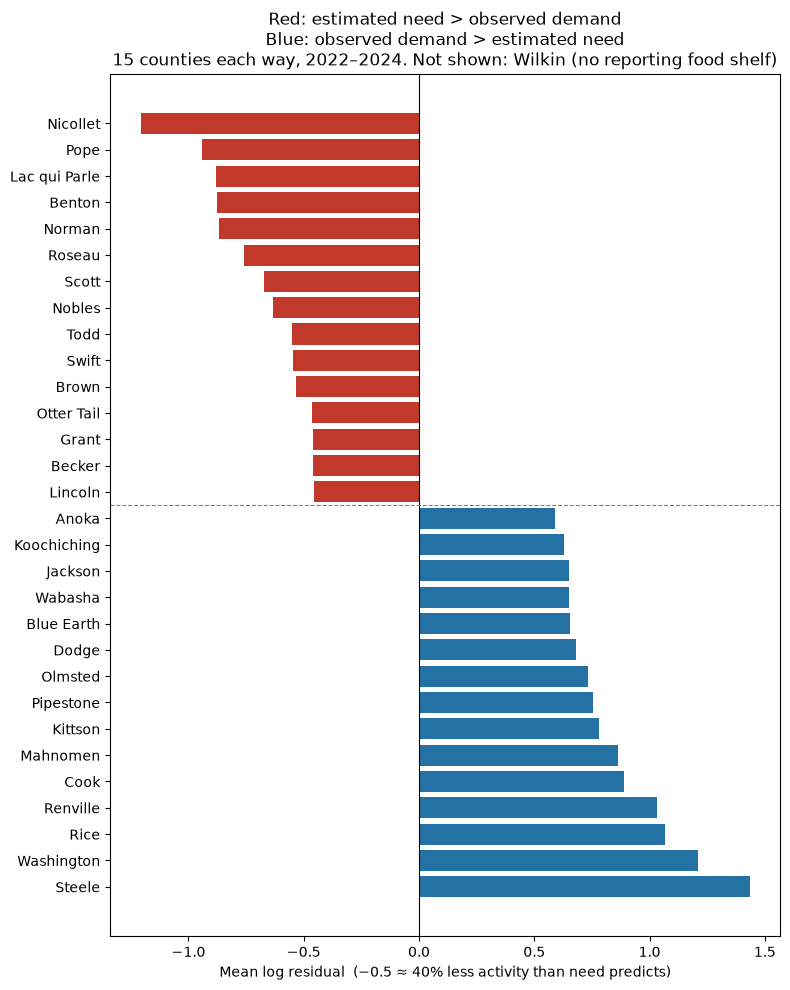

In [9]:
k = 15
show = pd.concat([summary.head(k), summary.tail(k)])
labels = [f"{c} *" if mm < 12 else c for c, mm in zip(show.index, show["min_months"])]
colors = ["#c0392b" if v < 0 else "#2471a3" for v in show["mean_resid"]]

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(range(len(show)), show["mean_resid"], color=colors)
ax.set_yticks(range(len(show)), labels)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.axhline(k - 0.5, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Mean log residual  (−0.5 ≈ 40% less activity than need predicts)")
ax.set_title("Red: estimated need > observed demand\n"
             "Blue: observed demand > estimated need\n"
             f"{k} counties each way, 2022–2024. Not shown: Wilkin (no reporting food shelf)")
plt.tight_layout()
plt.show()

## Sub-question 4: what explains the mismatch?

**Outcome:** the residual from the log-log fit above, averaged over the three metrics, one
row per county-year. Positive = more food-shelf activity than need predicts. Wilkin has no
residual (no activity) and is not in the model.

**Hypotheses, written before looking at any result.** Each one answers: *two counties with
the same number of food-insecure people; one has more X; does it have more or less
food-shelf activity?*

| variable | family | expected sign | mechanism | alternative |
|---|---|---|---|---|
| `mean_km_to_site` | rural | − | farther to travel | |
| `rucc` group (metro / non-metro town / rural) | rural | − for rural vs metro | harder to serve | grouping by metro adjacency was considered; town size chosen |
| `pct_no_vehicle` | deprivation | − | cannot reach the site or carry food home | |
| `pct_hh_snap` | deprivation | + | complement: households on SNAP are already connected to assistance | substitute (−): SNAP covers groceries, less need for a food shelf |
| `poverty_rate` | | side check only | input to the MMG model, so circular as an explanation | |

Left out on purpose: `sites_per_10k` (nearly restates the outcome), `log population` and
`pct_senior` (both move with `rucc`, Spearman about −0.8 and +0.7).

**Design:** county-years (3 per county), year dummies, standard errors clustered on
county because the three years of one county are not independent observations.

In [10]:
# One row per county-year: mean residual across the three metrics + the chosen covariates
q4 = (res.groupby(["fips", "county_name", "year"], as_index=False)["resid"].mean()
         .merge(df[["fips", "year", "mean_km_to_site", "rucc_2023", "pct_no_vehicle",
                    "pct_hh_snap", "poverty_rate"]], on=["fips", "year"], how="left"))

q4["rucc_group"] = pd.cut(q4["rucc_2023"], bins=[0, 3, 7, 9],
                          labels=["metro", "nonmetro_town", "rural"])

# z-scores: a coefficient then reads "effect of one standard deviation", comparable across variables
num = ["mean_km_to_site", "pct_no_vehicle", "pct_hh_snap", "poverty_rate"]
for v in num:
    q4[v + "_z"] = (q4[v] - q4[v].mean()) / q4[v].std()

q4["county_id"] = q4["fips"].astype("category").cat.codes   # integer id for clustering

# 0/1 dummies, written out by hand so every column in the model is visible.
# Baselines: metro counties, year 2022.
q4["nonmetro_town"] = (q4["rucc_group"] == "nonmetro_town").astype(int)
q4["rural"] = (q4["rucc_group"] == "rural").astype(int)
q4["y2023"] = (q4["year"] == 2023).astype(int)
q4["y2024"] = (q4["year"] == 2024).astype(int)

print(q4.shape, "|", q4["fips"].nunique(), "counties |", q4[num].isna().sum().sum(), "missing covariate values")
q4.groupby("rucc_group", observed=True)["fips"].nunique()

(258, 19) | 86 counties | 0 missing covariate values


rucc_group
metro            27
nonmetro_town    25
rural            34
Name: fips, dtype: int64

### Look before modelling
Spearman of each candidate against the residual, then how the candidates relate to each
other. Compare the signs with the hypothesis table above.

,spearman_with_resid
mean_km_to_site,-0.229
pct_no_vehicle,-0.080
pct_hh_snap,-0.111
poverty_rate,-0.122
rucc_2023,-0.040


,mean_km_to_site,pct_no_vehicle,pct_hh_snap,poverty_rate,rucc_2023
mean_km_to_site,1.00,-0.12,0.14,0.25,0.53
pct_no_vehicle,-0.12,1.00,0.55,0.55,-0.05
pct_hh_snap,0.14,0.55,1.00,0.72,0.24
poverty_rate,0.25,0.55,0.72,1.00,0.40
rucc_2023,0.53,-0.05,0.24,0.40,1.00


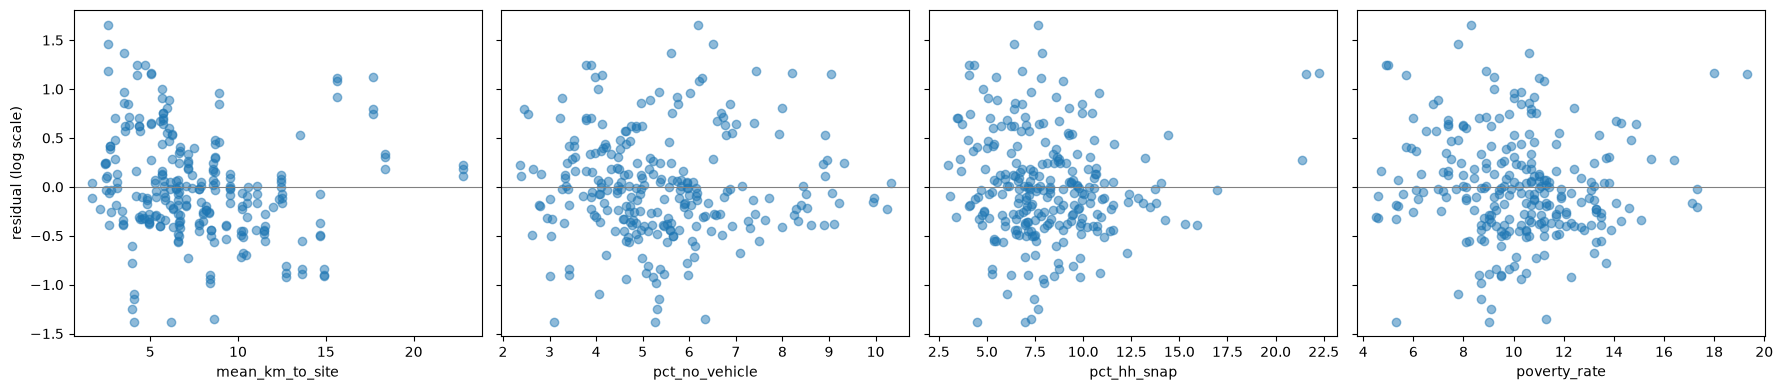

,mean,median,count
rucc_group,,,
metro,0.048,-0.031,81
nonmetro_town,-0.067,-0.164,75
rural,0.011,-0.006,102


In [11]:
look = pd.DataFrame({
    "spearman_with_resid": [q4[v].corr(q4["resid"], method="spearman") for v in num + ["rucc_2023"]],
}, index=num + ["rucc_2023"]).round(3)
display(look)
display(q4[num + ["rucc_2023"]].corr(method="spearman").round(2))

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, v in zip(axes, num):
    ax.scatter(q4[v], q4["resid"], alpha=0.5)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel(v)
axes[0].set_ylabel("residual (log scale)")
plt.tight_layout()
plt.show()

q4.groupby("rucc_group", observed=True)["resid"].agg(["mean", "median", "count"]).round(3)

### The model (fit once)
Read each coefficient as: the change in the residual for a one standard deviation increase
in that variable, holding the others fixed. `nonmetro_town` and `rural` are compared
against metro counties; `y2023` and `y2024` against 2022. Residuals are on a log scale, so a coefficient of −0.10 is roughly 10% less
activity than need predicts.

In [12]:
def coef_table(fit):
    """Coefficients with clustered standard errors, p-values and 95% intervals."""
    ci = fit.conf_int()
    return pd.DataFrame({"coef": fit.params, "se": fit.bse, "p": fit.pvalues,
                         "ci_low": ci[0], "ci_high": ci[1]}).round(3)

def fit_clustered(formula, data):
    return smf.ols(formula, data=data).fit(cov_type="cluster",
                                          cov_kwds={"groups": data["county_id"]})

COVARIATES = ("mean_km_to_site_z + nonmetro_town + rural "
              "+ pct_no_vehicle_z + pct_hh_snap_z + y2023 + y2024")

m_main = fit_clustered("resid ~ " + COVARIATES, q4)
print("n =", int(m_main.nobs), "| counties =", q4["county_id"].nunique(), "| R2 =", round(m_main.rsquared, 3))
coef_table(m_main)

n = 258 | counties = 86 | R2 = 0.033


,coef,se,p,ci_low,ci_high
Intercept,-0.026,0.119,0.825,-0.260,0.207
mean_km_to_site_z,-0.103,0.074,0.163,-0.247,0.042
nonmetro_town,-0.056,0.151,0.712,-0.353,0.241
rural,0.096,0.152,0.527,-0.201,0.393
pct_no_vehicle_z,-0.008,0.056,0.881,-0.118,0.101
pct_hh_snap_z,-0.016,0.078,0.836,-0.169,0.136
y2023,0.000,0.027,0.999,-0.052,0.052
y2024,0.014,0.045,0.758,-0.074,0.102


### Side check: add poverty
Poverty is an input to the MMG need estimate, so this is not part of the explanation. It
answers a different question: do the other coefficients change when poverty is held fixed?

In [13]:
m_pov = fit_clustered("resid ~ " + COVARIATES + " + poverty_rate_z", q4)
print("R2 =", round(m_pov.rsquared, 3))
pd.concat({"main": coef_table(m_main)[["coef", "p"]],
           "with poverty": coef_table(m_pov)[["coef", "p"]]}, axis=1)

R2 = 0.034


main        with poverty       
                    coef      p         coef      p
Intercept         -0.026  0.825       -0.034  0.784
mean_km_to_site_z -0.103  0.163       -0.099  0.184
nonmetro_town     -0.056  0.712       -0.046  0.773
rural              0.096  0.527        0.109  0.508
pct_no_vehicle_z  -0.008  0.881        0.000  0.996
pct_hh_snap_z     -0.016  0.836       -0.002  0.982
y2023              0.000  0.999        0.001  0.978
y2024              0.014  0.758        0.012  0.780
poverty_rate_z       NaN    NaN       -0.028  0.725

### Appendix: one model per metric
Same model, fitted to each metric's own residual instead of the average. If the three
columns agree in sign, the averaged model is a fair summary.

In [14]:
cov = q4.drop(columns=["resid"])
per_metric = {}
for met in ["households", "pounds", "individuals"]:
    d = res[res["metric"] == met][["fips", "year", "resid"]].merge(cov, on=["fips", "year"])
    per_metric[met] = coef_table(fit_clustered("resid ~ " + COVARIATES, d))[["coef", "p"]]
pd.concat(per_metric, axis=1)

households        pounds        individuals       
                        coef      p   coef      p        coef      p
Intercept              0.004  0.973 -0.068  0.522      -0.015  0.911
mean_km_to_site_z     -0.083  0.295 -0.110  0.105      -0.116  0.141
nonmetro_town         -0.079  0.638 -0.006  0.966      -0.083  0.626
rural                  0.040  0.805  0.160  0.238       0.087  0.611
pct_no_vehicle_z      -0.015  0.801 -0.002  0.969      -0.008  0.900
pct_hh_snap_z         -0.005  0.950 -0.031  0.696      -0.012  0.876
y2023                 -0.001  0.972  0.002  0.950      -0.001  0.981
y2024                  0.009  0.836  0.018  0.712       0.014  0.760

### Robustness: one step instead of two
The model above works in two steps (fit activity on need, then explain what is left). If a
covariate is itself related to the number of food-insecure people, two steps can understate
its effect. This fits everything at once for households; the covariate coefficients should
look similar to the two-step households column.

In [15]:
one = df[df["households"] > 0].merge(
    q4[["fips", "year", "nonmetro_town", "rural", "y2023", "y2024", "county_id"]
       + [v + "_z" for v in num]], on=["fips", "year"])
m_one = fit_clustered("np.log(households) ~ np.log(fi_persons) + " + COVARIATES, one)
pd.concat({"two-step (households)": per_metric["households"],
           "one-step (households)": coef_table(m_one)[["coef", "p"]]}, axis=1)

two-step (households)        one-step (households)       
                                    coef      p                  coef      p
Intercept                          0.004  0.973                -0.357  0.569
mean_km_to_site_z                 -0.083  0.295                -0.088  0.273
nonmetro_town                     -0.079  0.638                -0.107  0.534
rural                              0.040  0.805                -0.022  0.907
pct_no_vehicle_z                  -0.015  0.801                -0.003  0.964
pct_hh_snap_z                     -0.005  0.950                -0.009  0.910
y2023                             -0.001  0.972                 0.130  0.000
y2024                              0.009  0.836                 0.150  0.001
np.log(fi_persons)                   NaN    NaN                 1.139  0.000